#  Exploratory Data Analysis

## Objective

The objective of this notebook is to understand the structure,
quality, distribution, and main characteristics of the transaction
dataset before performing preprocessing and machine learning.

We will investigate:

- Dataset structure
- Data types
- Missing values
- Duplicates
- Target distribution
- Numerical variables
- Categorical variables
- Transaction distributions
- Potential anomalies
- Potential data leakage
- Initial fraud patterns

## Import labraries

In [1]:
import pandas as pd  
from pathlib import Path
import matplotlib.pyplot as plt 

## Load the raw dataset

In [2]:
PATH = Path('../data/raw/fraud_detection_data.csv')
data=pd.read_csv(PATH)

In [3]:
data.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


## Understand the dataset structure

In [4]:
data.shape

(6362620, 11)

## Data type 

In [5]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            str    
 2   amount          float64
 3   nameOrig        str    
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        str    
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 534.0 MB


## Missing value

In [6]:
data.isnull().sum()

step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

## Duplicates

In [7]:
data.duplicated().sum()

np.int64(0)

## Basic statistic

In [15]:
data.describe()

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
count,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06
mean,2.433972e+02,1.798619e+05,8.338831e+05,8.551137e+05,1.100702e+06,1.224996e+06,1.290820e-03,2.514687e-06
std,1.423320e+02,6.038582e+05,2.888243e+06,2.924049e+06,3.399180e+06,3.674129e+06,3.590480e-02,1.585775e-03
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.560000e+02,1.338957e+04,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,2.390000e+02,7.487194e+04,1.420800e+04,0.000000e+00,1.327057e+05,2.146614e+05,0.000000e+00,0.000000e+00
75%,3.350000e+02,2.087215e+05,1.073152e+05,1.442584e+05,9.430367e+05,1.111909e+06,0.000000e+00,0.000000e+00
max,7.430000e+02,9.244552e+07,5.958504e+07,4.958504e+07,3.560159e+08,3.561793e+08,1.000000e+00,1.000000e+00


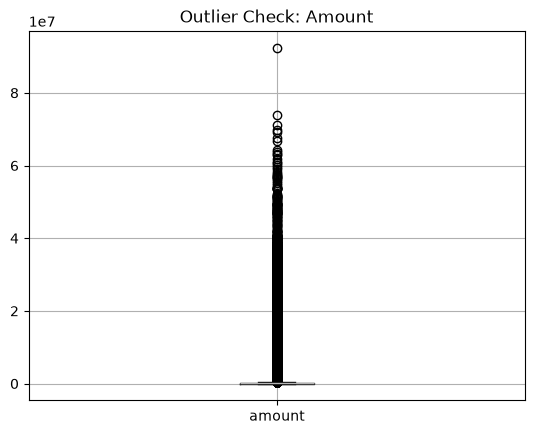

In [17]:
data.boxplot(column='amount')  # replace with your numeric column
plt.title("Outlier Check: Amount")
plt.show()

The amount column contains a significant number of outliers . These outliers were not removed or handled, as they likely represent genuine high-value transactions rather than errors, and may be important indicators of fraud.

## Target

### Identify the Target

In [9]:
data['isFraud'].value_counts(normalize=True) * 100

isFraud
0    99.870918
1     0.129082
Name: proportion, dtype: float64

This immediatly tell us that we have a highly imbalanced classification problem

### Visualize the target destribution

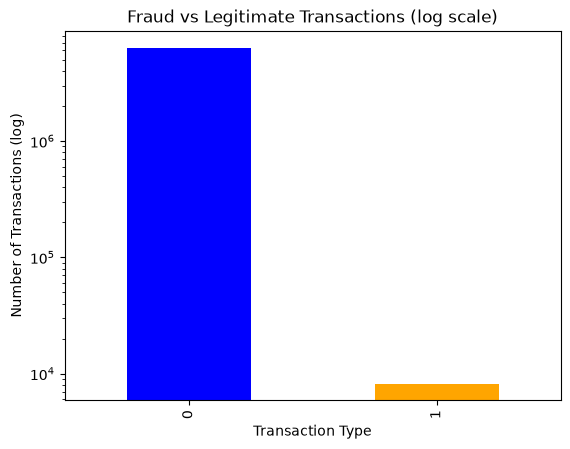

In [ ]:
data['isFraud'].value_counts().plot(kind="bar", color=["blue", "orange"])
plt.yscale('log')  
plt.title("Fraud vs Legitimate Transactions (log scale)")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions (log)")
plt.show()

##  Conclusion

### Key findings

- The dataset contains **6362620 transactions** and **11 features**.
- The target variable is **`isFraud`**.
- The dataset has neither a  **missing values** nor a **duplicate rows**.
- The target variable is **highly imbalanced**, with fraudulent transactions representing approximately **0.13%** of the dataset.


### Next step

The next notebook, `02_data_cleaning.ipynb`, will focus on preparing
the dataset for machine learning by addressing data quality issues
identified during this exploratory analysis.